In [117]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
import phik


load_dotenv(find_dotenv(usecwd=True))
url = URL.create("postgresql+psycopg2",
    username=os.getenv("DB_USER"), password=os.getenv("DB_PASSWORD"),
    host="localhost", port=5433, database="hotel")
engine = create_engine(url)

df = pd.read_sql("SELECT * FROM hotels", engine)

print(df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df['is_canceled'].mean())



(119390, 32)
(87396, 32)
0.27489816467572886


In [118]:
print("дублей:", df.duplicated().sum(), f"({df.duplicated().mean():.1%})")

vc = df.value_counts(dropna=False)
print(vc[vc > 1].describe())          # сколько копий у повторяющихся строк

mask = df.duplicated(keep=False)
print("доля отмен среди дублей:", df.loc[mask, "is_canceled"].mean())
print("доля отмен во всём датасете:", df["is_canceled"].mean())

дублей: 0 (0.0%)
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: count, dtype: float64
доля отмен среди дублей: nan
доля отмен во всём датасете: 0.27489816467572886


In [119]:
df["total_night"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df = df.drop(columns=["company","assigned_room_type","distribution_channel", "reservation_status", "reservation_status_date", "stays_in_weekend_nights", "stays_in_week_nights", "arrival_date_year", "arrival_date_month"])



In [120]:
ct = pd.crosstab(df["agent"], df["hotel"])
print("агентов в обоих отелях:", (ct > 0).all(axis=1).sum(), "из", len(ct))
print(ct.sort_values(ct.columns.tolist(), ascending=False).head(20))

агентов в обоих отелях: 75 из 333
hotel  City Hotel  Resort Hotel
agent                          
9.0         28753             6
14.0         3349             0
7.0          3300             0
28.0         1502             0
1.0          1226             6
8.0          1118           265
83.0          614             0
6.0           540           577
85.0          524             0
27.0          395             0
22.0          345             0
3.0           336            27
11.0          273            45
138.0         257             0
37.0          225             0
229.0         218             0
16.0          216             4
10.0          201            13
21.0          199             0
42.0          194             0


In [121]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87396 entries, 0 to 87395
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87396 non-null  str    
 1   is_canceled                     87396 non-null  int64  
 2   lead_time                       87396 non-null  int64  
 3   arrival_date_week_number        87396 non-null  int64  
 4   arrival_date_day_of_month       87396 non-null  int64  
 5   adults                          87396 non-null  int64  
 6   children                        87396 non-null  str    
 7   babies                          87396 non-null  int64  
 8   meal                            87396 non-null  str    
 9   country                         86944 non-null  str    
 10  market_segment                  87396 non-null  str    
 11  is_repeated_guest               87396 non-null  int64  
 12  previous_cancellations          87396 non-n

In [122]:
df.describe()

,is_canceled,lead_time,arrival_date_week_number,arrival_date_day_of_month,adults,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,total_night
count,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,75203.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000
mean,0.274898,79.891368,26.838334,15.815541,1.875795,0.010824,0.039075,0.030413,0.183990,0.271603,94.138306,0.749565,106.337246,0.084226,0.698567,3.630658
std,0.446466,86.052325,13.674572,8.835146,0.626500,0.113597,0.193775,0.369145,1.731894,0.727245,113.188172,10.015731,55.013953,0.281533,0.831946,2.763449
min,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,-6.380000,0.000000,0.000000,0.000000
25%,0.000000,11.000000,16.000000,8.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,72.000000,0.000000,0.000000,2.000000
50%,0.000000,49.000000,27.000000,16.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,98.100000,0.000000,0.000000,3.000000
75%,1.000000,125.000000,37.000000,23.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,0.000000,134.000000,0.000000,1.000000,5.000000
max,1.000000,737.000000,53.000000,31.000000,55.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,391.000000,5400.000000,8.000000,5.000000,69.000000


In [ ]:
df.isnull().sum()

In [124]:
df['country'] =df['country'].fillna("PRT")

In [125]:
df['agent'] = df['agent'].fillna(0)

In [ ]:
df.isnull().sum()

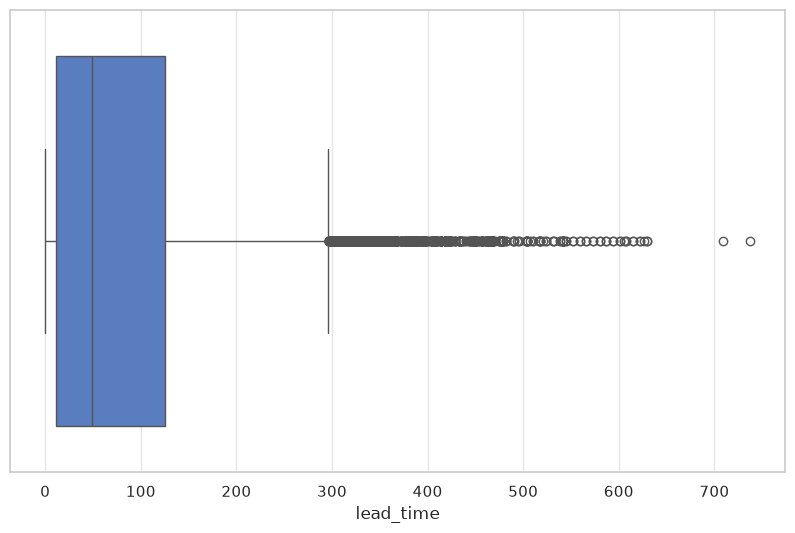

In [127]:
plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=df, x='lead_time')


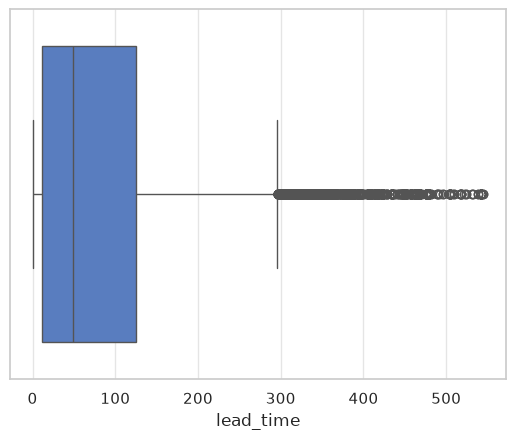

In [129]:
df = df[df['lead_time'] < 600]
ax = sns.boxplot(data=df, x='lead_time')

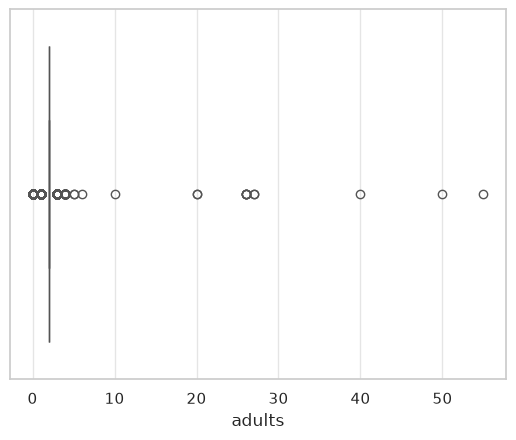

In [132]:
ax = sns.boxplot(data=df, x='adults')


люди с 4мя взрослыми еще могут отказаться а взрослых больше 4 уже все по головно класса 1, поэтому удалять выбросы не буду, модель сама поймет что если заселяется целое село то они много вероятно заселятся

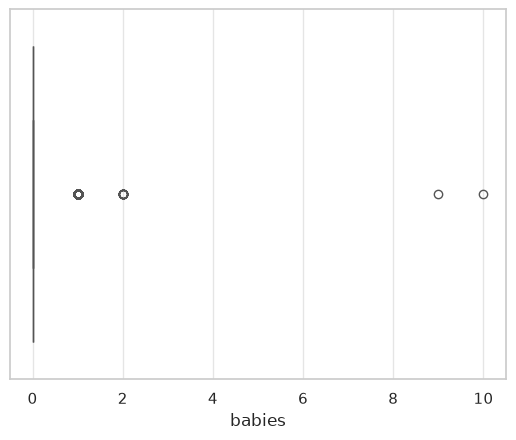

In [133]:
ax = sns.boxplot(data=df, x='babies')


2 из 17 людей с детьми is_canceled - 1 , остальные 0

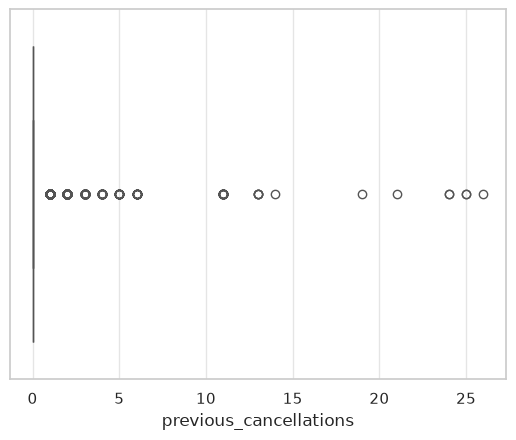

In [135]:

ax = sns.boxplot(data=df, x='previous_cancellations')


sql показал что сам по себе признак из себя не чего толком не представляет, 98% - это 0, удалять не буду, плюса к метрикам толком не получу.